# RNN (Recurrent Neural Network) — Temelden Uygulamaya
### PyTorch ve Keras ile satır satır açıklamalı

**İçerik**
1. RNN nedir? Algoritmanın en temel anlatımı
2. Elle küçük bir sayısal örnek (NumPy)
3. Veri hazırlama (gürültülü sinüs dalgası)
4. **PyTorch** ile RNN — elle yazılmış hücre + hazır `nn.RNN`
5. **Keras** ile RNN — `SimpleRNN`
6. Karşılaştırma, zayıf noktalar ve LSTM/GRU

**Görev:** Bir sinüs dalgasının son 20 değerine bakıp **bir sonraki** değeri tahmin etmek.

## 1. RNN nedir? En temelden

### 1.1 Problem: sıra önemli olduğunda
Normal bir sinir ağı (MLP) girdiyi **tek parça** olarak görür ve **hafızası yoktur**.
Oysa *"bugün hava çok ___"* cümlesindeki boşluğu doldurmak için önceki kelimeleri bilmek gerekir.
Borsa fiyatı, ses, metin ve sensör verisinde **sıra bilgi taşır**. RNN bu tür veriler için tasarlanmıştır.

### 1.2 Temel fikir: bir hafıza (gizli durum $h$)
RNN diziyi **adım adım** okur ve her adımda bir "not defterini" günceller. Bu nota **gizli durum** ($h_t$) denir.
Yeni not iki şeyin birleşimidir:
- şu anki girdi $x_t$
- bir önceki not $h_{t-1}$

### 1.3 Tek formül: RNN'in kalbi

$$h_t = \tanh\left(W_{xh}\, x_t + W_{hh}\, h_{t-1} + b_h\right)$$

$$\hat{y} = W_{hy}\, h_T + b_y$$

| Sembol | Anlamı |
|---|---|
| $x_t$ | $t$ anındaki girdi |
| $h_t$ | $t$ anındaki gizli durum (hafıza) |
| $W_{xh}$ | Yeni girdiye ne kadar önem verileceği |
| $W_{hh}$ | Geçmiş hafızaya ne kadar önem verileceği |
| $\tanh$ | Değerleri $[-1, 1]$ aralığına sıkıştırır |
| $\hat{y}$ | Son hafızadan üretilen tahmin |

> **Kritik nokta:** Aynı ağırlıklar ($W_{xh}, W_{hh}$) **her zaman adımında yeniden kullanılır**.
> 20 adımlık dizi için 20 ayrı ağ yoktur; **tek bir hücre 20 kez çalışır**. Bu yüzden RNN her uzunluktaki diziyi işleyebilir.

### 1.4 "Açılmış" (unrolled) görünüm
```
 x₁        x₂        x₃              x₂₀
 ↓         ↓         ↓               ↓
[RNN]→h₁→[RNN]→h₂→[RNN]→h₃ … →[RNN]→h₂₀ → Dense → ŷ
   ↑──────── aynı hücre, aynı ağırlıklar ────────↑
```

### 1.5 Nasıl öğrenir? Zamanda Geri Yayılım (BPTT)
1. **İleri yayılım:** dizi baştan sona işlenir, tahmin $\hat{y}$ üretilir.
2. **Kayıp:** hata hesaplanır, örn. $\text{MSE} = (\hat{y} - y)^2$.
3. **Geri yayılım:** hata açılmış zincir boyunca **son adımdan ilk adıma** taşınır. Ağırlıklar paylaşıldığı için her adımın gradyanı **toplanır**:
$$\frac{\partial L}{\partial W_{hh}} = \sum_{t=1}^{T} \frac{\partial L}{\partial h_t}\,\frac{\partial h_t}{\partial W_{hh}}$$
4. **Güncelleme:** optimizer (Adam) ağırlıkları hatayı azaltacak yönde kaydırır.

## 2. Elle küçük bir sayısal örnek

Girdi dizisi $[0.5,\ 0.8]$, gizli boyut 1, $W_{xh}=1$, $W_{hh}=0.5$, $b=0$ olsun:
- $h_0 = 0$ (hafıza boş)
- $h_1 = \tanh(1\cdot 0.5 + 0.5\cdot 0) = \tanh(0.5) \approx 0.46$
- $h_2 = \tanh(1\cdot 0.8 + 0.5\cdot 0.46) = \tanh(1.03) \approx 0.77$

$h_2$ hem 0.8'i hem de önceki 0.5'i "hatırlıyor". Aşağıdaki hücre bunu NumPy ile hesaplıyor:

In [1]:
import numpy as np                      # Sayısal hesaplama kütüphanesi

x_dizi = [0.5, 0.8]                     # 2 adımlık girdi dizisi
W_xh, W_hh, b = 1.0, 0.5, 0.0           # Elle seçilmiş ağırlıklar (gizli boyut = 1)
h = 0.0                                 # h_0: başlangıçta hafıza boş

for t, x_t in enumerate(x_dizi, start=1):   # Diziyi soldan sağa adım adım oku
    h = np.tanh(W_xh * x_t + W_hh * h + b)  # RNN formülü: yeni hafıza = tanh(girdi + eski hafıza)
    print(f"h_{t} = {h:.4f}")               # Her adımdaki gizli durumu yazdır

h_1 = 0.4621
h_2 = 0.7743


## 3. Veri hazırlama

Gürültülü bir sinüs dalgası üretiyoruz ve **kayan pencere** ile örneklere bölüyoruz:
- **Girdi:** ardışık 20 değer → şekil `(N, 20, 1)` = (örnek sayısı, zaman adımı, özellik sayısı)
- **Hedef:** hemen sonraki değer → şekil `(N, 1)`

Bu veri hem PyTorch hem Keras bölümünde ortak kullanılacak.

In [2]:
import matplotlib.pyplot as plt         # Grafik çizmek için

np.random.seed(42)                      # Gürültü her çalıştırmada aynı olsun (tekrarlanabilirlik)

t = np.linspace(0, 100, 2000)           # 0 ile 100 arasında eşit aralıklı 2000 zaman noktası
seri = np.sin(t) + 0.05 * np.random.randn(len(t))  # Sinüs + biraz gürültü → gerçekçi zaman serisi

PENCERE = 20                            # Model geçmişteki 20 adıma bakacak (dizi uzunluğu T)

X, y = [], []                           # Girdi pencereleri ve hedefler için boş listeler
for i in range(len(seri) - PENCERE):    # Seri boyunca pencereyi birer adım kaydır
    X.append(seri[i:i + PENCERE])       # Girdi: i..i+19 arasındaki 20 değer
    y.append(seri[i + PENCERE])         # Hedef: hemen ardından gelen 21. değer

X = np.array(X, dtype="float32")[..., None]  # (N, 20) → (N, 20, 1): her adımda 1 özellik
y = np.array(y, dtype="float32")[:, None]    # (N,) → (N, 1): her örnek için tek hedef

bolme = int(0.8 * len(X))               # Verinin %80'i eğitim, %20'si test
X_egitim_np, y_egitim_np = X[:bolme], y[:bolme]
X_test_np,   y_test_np   = X[bolme:], y[bolme:]

print("X şekli:", X.shape, "| y şekli:", y.shape)
print("Eğitim:", X_egitim_np.shape[0], "örnek | Test:", X_test_np.shape[0], "örnek")

X şekli: (1980, 20, 1) | y şekli: (1980, 1)
Eğitim: 1584 örnek | Test: 396 örnek


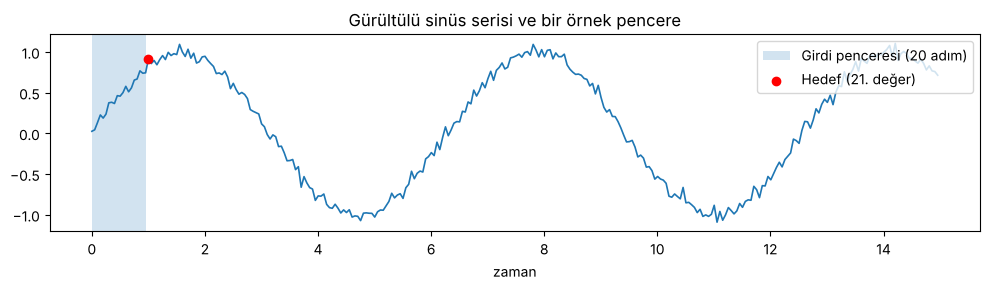

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))         # Geniş ve alçak bir grafik alanı
ax.plot(t[:300], seri[:300], lw=1.2)            # Serinin ilk 300 noktasını çiz
ax.axvspan(t[0], t[PENCERE - 1], alpha=0.2, label="Girdi penceresi (20 adım)")  # İlk pencereyi boya
ax.scatter(t[PENCERE], seri[PENCERE], color="red", zorder=3, label="Hedef (21. değer)")  # Hedef noktası
ax.set_title("Gürültülü sinüs serisi ve bir örnek pencere")
ax.set_xlabel("zaman"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 4. PyTorch ile RNN

### 4.1 Önce temel: RNN hücresini **elle** yazalım
Formül: $h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b)$. Bu sınıf formülü birebir kodlar; `nn.RNN`'in içinde olan da budur.

In [4]:
import torch                            # PyTorch çekirdeği: tensörler + otomatik türev
import torch.nn as nn                   # Hazır katmanlar: nn.RNN, nn.Linear, kayıp fonksiyonları
from torch.utils.data import TensorDataset, DataLoader  # Veriyi mini-batch'lere bölmek için

torch.manual_seed(42)                   # Rastgele ağırlıklar her çalıştırmada aynı olsun

class ElleRNN(nn.Module):
    def __init__(self, girdi_boyutu, gizli_boyut):
        super().__init__()                                   # nn.Module kurucusunu çağır (zorunlu)
        self.gizli_boyut = gizli_boyut                       # Gizli durum vektörünün uzunluğu (H)
        self.W_xh = nn.Linear(girdi_boyutu, gizli_boyut)     # Girdi → gizli ağırlığı (+ bias)
        self.W_hh = nn.Linear(gizli_boyut, gizli_boyut, bias=False)  # Önceki gizli → yeni gizli ağırlığı

    def forward(self, x):                                    # x şekli: (B, T, girdi_boyutu)
        B, T, _ = x.shape                                    # B: batch boyutu, T: zaman adımı sayısı
        h = torch.zeros(B, self.gizli_boyut)                 # h_0: başlangıçta hafıza boş (sıfır)
        for t in range(T):                                   # Zamanda soldan sağa tek tek ilerle
            x_t = x[:, t, :]                                 # t anındaki girdi: (B, girdi_boyutu)
            h = torch.tanh(self.W_xh(x_t) + self.W_hh(h))    # RNN'in kalbi: yeni hafıza = f(girdi, eski hafıza)
        return h                                             # Son gizli durum: tüm diziyi "özetler"

elle = ElleRNN(girdi_boyutu=1, gizli_boyut=32)               # Kendi RNN hücremiz
ornek = torch.tensor(X_test_np[:3])                          # 3 örnek al
print("Elle RNN son gizli durum şekli:", tuple(elle(ornek).shape))  # (3, 32)

Elle RNN son gizli durum şekli: (3, 32)


### 4.2 Veriyi tensöre çevirme ve DataLoader

In [5]:
X_egitim = torch.tensor(X_egitim_np)    # NumPy dizisini PyTorch tensörüne çevir (float32)
y_egitim = torch.tensor(y_egitim_np)
X_test   = torch.tensor(X_test_np)
y_test   = torch.tensor(y_test_np)

egitim_yukleyici = DataLoader(          # Eğitim verisini 64'lük gruplar halinde verecek yükleyici
    TensorDataset(X_egitim, y_egitim),  # (girdi, hedef) çiftlerini tek veri kümesinde birleştir
    batch_size=64,                      # Her adımda 64 örnek işlenir
    shuffle=True)                       # Her epoch'ta örneklerin sırası karıştırılır

### 4.3 Asıl model: hazır `nn.RNN` katmanı
`nn.RNN`, 4.1'deki döngünün hızlı ve optimize edilmiş hâlidir. Çıktısı iki şeydir:
- `cikislar`: **her adımın** gizli durumu `(B, T, H)`
- `h_son`: yalnızca **son** gizli durum `(katman_sayısı, B, H)`

In [6]:
class RNNModel(nn.Module):
    def __init__(self, girdi_boyutu=1, gizli_boyut=32, cikti_boyutu=1):
        super().__init__()
        self.rnn = nn.RNN(                  # Hazır RNN katmanı
            input_size=girdi_boyutu,        # Her zaman adımındaki özellik sayısı (burada 1)
            hidden_size=gizli_boyut,        # Gizli durum boyutu H = 32 ("hafızanın genişliği")
            num_layers=1,                   # Üst üste kaç RNN katmanı (1 = tek katman)
            nonlinearity="tanh",            # Aktivasyon fonksiyonu (varsayılan tanh)
            batch_first=True)               # Girdi şekli (B, T, F) olsun; False olsaydı (T, B, F)
        self.fc = nn.Linear(gizli_boyut, cikti_boyutu)  # Son gizli durumu tek tahmine çeviren katman

    def forward(self, x):                   # x: (B, 20, 1)
        cikislar, h_son = self.rnn(x)       # cikislar: (B, 20, 32); h_son: (1, B, 32)
        son_adim = cikislar[:, -1, :]       # Sadece son zaman adımının gizli durumu: (B, 32)
        return self.fc(son_adim)            # (B, 32) → (B, 1): bir sonraki değerin tahmini

model = RNNModel()                          # Modeli oluştur (ağırlıklar rastgele başlar)
print(model)                                # Katman yapısını yazdır
print("Parametre sayısı:", sum(p.numel() for p in model.parameters()))  # Toplam öğrenilebilir sayı

RNNModel(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Parametre sayısı: 1153


### 4.4 Kayıp fonksiyonu, optimizer ve eğitim döngüsü
PyTorch'ta eğitim döngüsünü **kendimiz** yazarız. Her mini-batch için 6 adım:
`zero_grad → ileri yayılım → kayıp → backward (BPTT) → gradyan kırpma → step`

In [7]:
kayip_fn = nn.MSELoss()                     # Ortalama kare hata: (tahmin - gerçek)^2 ortalaması
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  # Adam: ağırlıkları güncelleyen algoritma

EPOCH = 20                                  # Tüm eğitim verisinin üzerinden 20 kez geçilecek
pt_kayiplar = []                            # Her epoch'un kaybını grafik için sakla
for epoch in range(EPOCH):
    model.train()                           # Modeli eğitim moduna al
    toplam_kayip = 0.0                      # Bu epoch'taki kaybı biriktir
    for xb, yb in egitim_yukleyici:         # Her mini-batch için:
        optimizer.zero_grad()               # 1. Önceki gradyanları sıfırla (PyTorch biriktirir!)
        tahmin = model(xb)                  # 2. İleri yayılım: tahmin üret
        kayip = kayip_fn(tahmin, yb)        # 3. Tahmin ile gerçek arasındaki hata
        kayip.backward()                    # 4. Zamanda geri yayılım (BPTT): tüm gradyanları hesapla
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # 5. Gradyan patlamasına karşı kırp
        optimizer.step()                    # 6. Ağırlıkları gradyan yönünde güncelle
        toplam_kayip += kayip.item() * len(xb)  # Batch kaybını örnek sayısıyla ağırlıklandır
    ort = toplam_kayip / len(X_egitim)      # Epoch'un ortalama kaybı
    pt_kayiplar.append(ort)
    print(f"Epoch {epoch + 1:2d}/{EPOCH} | eğitim MSE: {ort:.5f}")

Epoch  1/20 | eğitim MSE: 0.30938
Epoch  2/20 | eğitim MSE: 0.03468
Epoch  3/20 | eğitim MSE: 0.01143
Epoch  4/20 | eğitim MSE: 0.00786


Epoch  5/20 | eğitim MSE: 0.00637
Epoch  6/20 | eğitim MSE: 0.00528
Epoch  7/20 | eğitim MSE: 0.00491
Epoch  8/20 | eğitim MSE: 0.00490


Epoch  9/20 | eğitim MSE: 0.00489
Epoch 10/20 | eğitim MSE: 0.00484
Epoch 11/20 | eğitim MSE: 0.00479
Epoch 12/20 | eğitim MSE: 0.00485


Epoch 13/20 | eğitim MSE: 0.00491
Epoch 14/20 | eğitim MSE: 0.00487
Epoch 15/20 | eğitim MSE: 0.00486


Epoch 16/20 | eğitim MSE: 0.00471
Epoch 17/20 | eğitim MSE: 0.00465
Epoch 18/20 | eğitim MSE: 0.00477
Epoch 19/20 | eğitim MSE: 0.00469


Epoch 20/20 | eğitim MSE: 0.00483


### 4.5 Test

In [8]:
model.eval()                                # Değerlendirme moduna al
with torch.no_grad():                       # Testte gradyan hesaplama (hız + bellek tasarrufu)
    pt_test_tahmin = model(X_test)          # Tüm test verisi için tahmin
    pt_test_mse = kayip_fn(pt_test_tahmin, y_test).item()  # Test hatası
print(f"PyTorch Test MSE: {pt_test_mse:.5f}\n")

for i in range(5):                          # İlk 5 test örneğinde tahmin vs gerçek
    print(f"Gerçek: {y_test[i].item():+.3f}   Tahmin: {pt_test_tahmin[i].item():+.3f}")

PyTorch Test MSE: 0.00442

Gerçek: -1.016   Tahmin: -0.988
Gerçek: -1.032   Tahmin: -1.002
Gerçek: -0.968   Tahmin: -1.008
Gerçek: -0.880   Tahmin: -0.996
Gerçek: -0.930   Tahmin: -0.952


## 5. Keras ile RNN

Keras'taki `SimpleRNN` aynı formülü uygular: $h_t = \tanh(x_t W + h_{t-1} U + b)$.
Fark şudur: PyTorch'ta elle yazdığımız eğitim döngüsünün tamamını Keras'ta **`fit()` tek satırda** yapar.

In [9]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # TensorFlow'un uzun bilgi mesajlarını gizle
import tensorflow as tf                  # Keras'ın üzerinde çalıştığı motor
from tensorflow import keras             # Yüksek seviyeli model API'si
from tensorflow.keras import layers      # Hazır katmanlar: SimpleRNN, Dense ...

tf.random.set_seed(42)                   # Rastgele başlangıç ağırlıkları tekrarlanabilir olsun

keras_model = keras.Sequential([         # Katmanları sırayla dizen basit model yapısı
    keras.Input(shape=(PENCERE, 1)),     # Girdi: 20 zaman adımı × 1 özellik (batch boyutu yazılmaz)
    layers.SimpleRNN(
        32,                              # Gizli durum boyutu H = 32
        activation="tanh",               # Aktivasyon (varsayılan zaten tanh)
        return_sequences=False),         # False: sadece SON h_t döner (B, 32)
                                         # True olsaydı her adımın h_t'si dönerdi (B, 20, 32)
    layers.Dense(1)                      # Son gizli durumu tek bir sayıya çevir (tahmin)
])
keras_model.summary()                    # Katmanları ve parametre sayılarını yazdır

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

### 5.1 Derleme ve eğitim

In [10]:
keras_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3,              # Öğrenme hızı
        clipnorm=1.0),                   # Gradyan kırpma: patlayan gradyanlara karşı koruma
    loss="mse",                          # Ortalama kare hata
    metrics=["mae"])                     # Ek olarak ortalama mutlak hatayı da izle

gecmis = keras_model.fit(                # zero_grad → ileri → kayıp → backward → step: hepsi burada
    X_egitim_np, y_egitim_np,            # Eğitim verisi (NumPy dizileri doğrudan verilebilir)
    epochs=20,                           # 20 tur
    batch_size=64,                       # Her adımda 64 örnek
    validation_split=0.1,                # Eğitim verisinin %10'unu doğrulama için ayır
    shuffle=True,                        # Her epoch'ta karıştır
    verbose=2)                           # Her epoch için tek satır özet yazdır

Epoch 1/20


23/23 - 2s - 83ms/step - loss: 0.1486 - mae: 0.2694 - val_loss: 0.0127 - val_mae: 0.0919


Epoch 2/20


23/23 - 0s - 5ms/step - loss: 0.0066 - mae: 0.0644 - val_loss: 0.0058 - val_mae: 0.0620


Epoch 3/20


...

23/23 - 0s - 6ms/step - loss: 0.0034 - mae: 0.0472 - val_loss: 0.0038 - val_mae: 0.0506


Epoch 19/20


23/23 - 0s - 6ms/step - loss: 0.0034 - mae: 0.0470 - val_loss: 0.0038 - val_mae: 0.0503


Epoch 20/20


23/23 - 0s - 6ms/step - loss: 0.0034 - mae: 0.0467 - val_loss: 0.0038 - val_mae: 0.0500


### 5.2 Test

In [11]:
k_test_mse, k_test_mae = keras_model.evaluate(X_test_np, y_test_np, verbose=0)  # Test kaybı ve metrik
print(f"Keras Test MSE: {k_test_mse:.5f} | Test MAE: {k_test_mae:.5f}\n")

k_test_tahmin = keras_model.predict(X_test_np, verbose=0)    # Tüm test verisi için tahmin
for gercek, tahmin in zip(y_test_np[:5, 0], k_test_tahmin[:5, 0]):
    print(f"Gerçek: {gercek:+.3f}   Tahmin: {tahmin:+.3f}")

Keras Test MSE: 0.00313 | Test MAE: 0.04373



Gerçek: -1.016   Tahmin: -0.962
Gerçek: -1.032   Tahmin: -0.983
Gerçek: -0.968   Tahmin: -0.963
Gerçek: -0.880   Tahmin: -0.943
Gerçek: -0.930   Tahmin: -0.924


## 6. Karşılaştırma

Aşağıda iki modelin eğitim kayıpları ve test tahminleri yan yana çiziliyor.

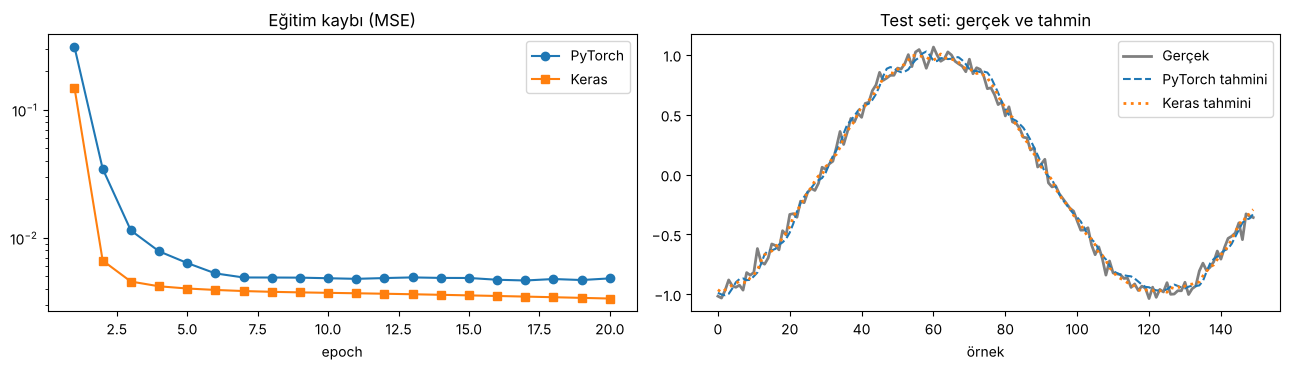

PyTorch Test MSE: 0.00442
Keras   Test MSE: 0.00313
Gürültünün kendi varyansı (ulaşılabilecek alt sınır ≈): 0.00250


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

# Sol: eğitim kaybı eğrileri
axes[0].plot(range(1, 21), pt_kayiplar, marker="o", label="PyTorch")
axes[0].plot(range(1, 21), gecmis.history["loss"], marker="s", label="Keras")
axes[0].set_yscale("log")                           # Kayıp hızla düştüğü için log ölçek
axes[0].set_title("Eğitim kaybı (MSE)"); axes[0].set_xlabel("epoch"); axes[0].legend()

# Sağ: test setinin ilk 150 noktasında gerçek vs tahmin
n = 150
axes[1].plot(y_test_np[:n, 0], color="black", lw=2, alpha=0.5, label="Gerçek")
axes[1].plot(pt_test_tahmin[:n, 0].numpy(), "--", label="PyTorch tahmini")
axes[1].plot(k_test_tahmin[:n, 0], ":", lw=2, label="Keras tahmini")
axes[1].set_title("Test seti: gerçek ve tahmin"); axes[1].set_xlabel("örnek"); axes[1].legend()

plt.tight_layout(); plt.show()

print(f"PyTorch Test MSE: {pt_test_mse:.5f}")
print(f"Keras   Test MSE: {k_test_mse:.5f}")
print(f"Gürültünün kendi varyansı (ulaşılabilecek alt sınır ≈): {0.05**2:.5f}")

| | PyTorch | Keras |
|---|---|---|
| RNN katmanı | `nn.RNN(..., batch_first=True)` | `layers.SimpleRNN(32)` |
| Son adımı alma | `cikislar[:, -1, :]` ile elle | `return_sequences=False` |
| Eğitim | Döngüyü sen yazarsın | `model.fit()` |
| Gradyan kırpma | `clip_grad_norm_` | `clipnorm=1.0` |
| Kime uygun | Kontrol ve araştırma | Hızlı prototip |

Parametre sayıları: PyTorch **1153**, Keras **1121**. Aradaki 32'lik fark, PyTorch'un RNN katmanında iki ayrı bias vektörü ($b_{ih}$ ve $b_{hh}$) tutmasından gelir; Keras tek bias kullanır. İki bias toplanınca tek bir bias'a eşdeğer olduğu için iki model matematiksel olarak aynı modeli kurar.

## 7. RNN'in zayıf noktası: kaybolan / patlayan gradyan

Geri yayılımda gradyan her adımda $W_{hh}$ ve $\tanh'$ ile **çarpılır**:
- Çarpan $< 1$ ise: $0.9^{50} \approx 0.005$ → gradyan **kaybolur**, ağ uzak geçmişi öğrenemez.
- Çarpan $> 1$ ise: $1.1^{50} \approx 117$ → gradyan **patlar**.

**Çözümler**
- Patlama için **gradyan kırpma** (kodda kullandık).
- Kaybolma için **LSTM** ve **GRU**: neyin hatırlanıp neyin unutulacağını öğrenen "kapılar" eklerler.

Denemek için:
- PyTorch: `nn.RNN` → `nn.LSTM` (dönüş değeri `cikislar, (h, c)` olur; `forward` aynı kalabilir)
- Keras: `layers.SimpleRNN` → `layers.LSTM`

In [13]:
print(f"0.9^50 = {0.9**50:.4f}   (kaybolan gradyan)")
print(f"1.1^50 = {1.1**50:.1f}   (patlayan gradyan)")

0.9^50 = 0.0052   (kaybolan gradyan)
1.1^50 = 117.4   (patlayan gradyan)
